# Lab 8 - Polynomial Regression

## Aim

To model a curved relationship with Polynomial Regression, to choose the polynomial
degree using cross-validation, and to demonstrate underfitting and overfitting.

## Theory

Polynomial Regression is still a *linear* model, but it is fitted on powers of the
feature:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

The **degree** $d$ controls flexibility:

- **Too low (underfitting / high bias):** the curve is too stiff to follow the real
  pattern, so both training and validation scores are poor.
- **Too high (overfitting / high variance):** the curve bends to fit noise in the
  training data and swings wildly where data is sparse, so the validation score drops.

The degree is a **hyper-parameter**, so it must be chosen on validation data
(cross-validation), never on the test set.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv`.

**Feature (X):** `soil_ph`. **Target (y):** `soil_health_card_score`.

The Soil Health Card rule gives a high "need" score to acidic soil (pH below 6.5) and
a low score to neutral soil, so the true relationship bends at pH 6.5 instead of
being a straight line. The feature is standardised before the powers are computed so
that $x^{15}$ does not become numerically huge.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("../ml/data/labeled_dataset.csv")

X = df[["soil_ph"]]
y = df["soil_health_card_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def poly_model(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))

Training samples: 1232 | Testing samples: 308


## Choosing the Degree with Cross-Validation

For each degree, the model is trained and scored with 5-fold cross-validation on the
training set. The training R² is also recorded: the gap between training and CV R²
is the sign of overfitting.

Chosen degree: 9


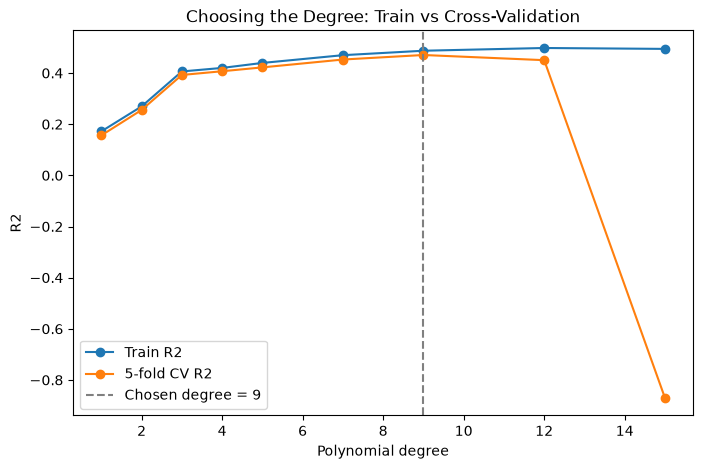

,Degree,Train R2,CV R2
0,1,0.1719,0.1562
1,2,0.2695,0.2557
2,3,0.4062,0.3925
3,4,0.4200,0.4070
4,5,0.4395,0.4221
5,7,0.4698,0.4528
6,9,0.4872,0.4705
7,12,0.4979,0.4503
8,15,0.4944,-0.8705


In [2]:
degrees = [1, 2, 3, 4, 5, 7, 9, 12, 15]
rows = []
for d in degrees:
    m = poly_model(d).fit(X_train, y_train)
    rows.append({"Degree": d,
                 "Train R2": round(r2_score(y_train, m.predict(X_train)), 4),
                 "CV R2": round(cross_val_score(poly_model(d), X_train, y_train, cv=cv, scoring="r2").mean(), 4)})
results = pd.DataFrame(rows)

best_cv = results["CV R2"].max()
# simplest degree whose CV R2 is within 0.01 of the best
best_degree = int(results.loc[results["CV R2"] >= best_cv - 0.01, "Degree"].min())
print("Chosen degree:", best_degree)

plt.figure(figsize=(8, 5))
plt.plot(results["Degree"], results["Train R2"], marker="o", label="Train R2")
plt.plot(results["Degree"], results["CV R2"], marker="o", label="5-fold CV R2")
plt.axvline(best_degree, color="grey", linestyle="--", label=f"Chosen degree = {best_degree}")
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Choosing the Degree: Train vs Cross-Validation")
plt.legend()
plt.show()

results

## Fitted Curves

The chosen degree is drawn together with a straight line (degree 1) and a very high
degree (15) for comparison.

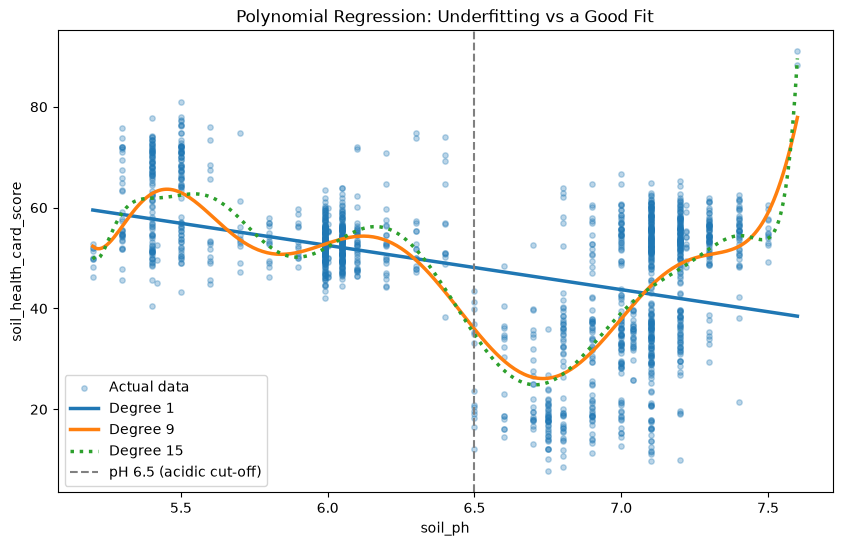

In [3]:
x_line = pd.DataFrame({"soil_ph": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})

plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.3, s=15, label="Actual data")
for d, style in [(1, "-"), (best_degree, "-"), (15, ":")]:
    plt.plot(x_line, poly_model(d).fit(X_train, y_train).predict(x_line),
             linestyle=style, linewidth=2.5, label=f"Degree {d}")
plt.axvline(6.5, color="grey", linestyle="--", label="pH 6.5 (acidic cut-off)")
plt.xlabel("soil_ph")
plt.ylabel("soil_health_card_score")
plt.title("Polynomial Regression: Underfitting vs a Good Fit")
plt.legend()
plt.show()

## Final Evaluation on the Test Set

The chosen degree is evaluated once on the test set.

In [4]:
final = poly_model(best_degree).fit(X_train, y_train)
y_pred = final.predict(X_test)
print(f"Degree {best_degree} - Test R2: {r2_score(y_test, y_pred):.4f} | Test MAE: {mean_absolute_error(y_test, y_pred):.3f}")
print(f"Degree 1 (straight line) - Test R2: {poly_model(1).fit(X_train, y_train).score(X_test, y_test):.4f}")

Degree 9 - Test R2: 0.5520 | Test MAE: 7.717
Degree 1 (straight line) - Test R2: 0.1489


## A Clear Overfitting Example

With soil pH there are many points across the whole range, so even high degrees stay
fairly stable. `elevation_m` against `jjm_score` is different: the data has gaps and
very few points at the edges. There, a high-degree polynomial bends wildly between
points; it still fits the training data, but its predictions on unseen data explode.

In [5]:
X_e = df[["elevation_m"]]
y_e = df["jjm_score"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_e, y_e, test_size=0.2, random_state=42)

rows = []
for d in [1, 3, 5, 9, 15]:
    m = poly_model(d).fit(Xe_train, ye_train)
    rows.append({"Degree": d,
                 "Train R2": round(r2_score(ye_train, m.predict(Xe_train)), 3),
                 "Test R2": round(r2_score(ye_test, m.predict(Xe_test)), 3)})
pd.DataFrame(rows)

,Degree,Train R2,Test R2
0,1,0.009,-0.042
1,3,0.529,0.501
2,5,0.548,0.533
3,9,0.563,-3.871
4,15,0.540,-1726.912


## Conclusion

Polynomial Regression was used to model `soil_health_card_score` from `soil_ph`.

| Degree | Train R² | CV R² | Comment |
|---|---|---|---|
| 1 | 0.172 | 0.156 | Underfits: a straight line cannot bend at pH 6.5 |
| 3 | 0.406 | 0.393 | Captures most of the bend |
| 9 | 0.487 | 0.471 | Chosen: best CV R² |
| 15 | 0.494 | -0.871 | Overfits: CV R² collapses |

**Observations**

1. **Underfitting:** degree 1 explains only about 16% of the variation; the test R²
   is 0.149.
2. **Choosing the degree by CV:** the CV R² rises until degree 9 and then falls. With
   degree 9 the test R² is 0.552 (MAE 7.7 points), almost four times the straight line.
3. **Overfitting:** at degree 15 the training R² is still about 0.49 but the CV R²
   drops to -0.87. The curve swings wildly in parts of the pH range with few plots.
   The elevation example shows the same effect even more strongly: test R² falls from
   0.533 (degree 5) to -3.87 (degree 9) and -1,727 (degree 15) while the training R²
   stays near 0.55.
4. **Limits:** pH alone cannot explain the whole score (best R² about 0.55), because
   the Soil Health Card rule also depends on organic carbon. Lab 13 shows that a model
   using both soil features does much better.
